# Explore the Data

### Imports

In [1]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

### Get the train set to explore

In [2]:
data = pd.read_parquet('train_set.parquet')

### Looking into each feature and its attributes.

| Name | Type | % Missing | Noisiness & Noise Type | Usefulness for Task | Type of Distribution |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `year` | Structured Numerical (Bounded: 1947–2025) | 0.00% | Deterministic (no noise) | Low to Moderate (captures long-term climate drift / warming trends) | Uniform (sequential annual index) |
| `phil_pred` | Categorical (Binary) | 0.00% | High noise (stochastic prediction & subjective human interpretation) | Low to Moderate (baseline heuristic; groundhog accuracy ~39%) | Binary / Bernoulli |
| `farm_avg_temp_mean_feb` | Bounded Numerical (°F) | 0.00% | Low to Moderate (stochastic daily weather fluctuations, station rounding) | High (direct thermal indicator of late-winter local warming) | Gaussian / Normal (skew = 0.02) |
| `farm_avg_temp_mean_jan` | Bounded Numerical (°F) | 1.75% | Low to Moderate (stochastic daily weather fluctuations, missing data) | Moderate (early winter thermal baseline) | Gaussian / Normal (skew = 0.08) |
| `farm_min_temp_min_feb` | Bounded Numerical (°F) | 0.00% | Moderate (arctic snap outliers, sensor noise) | Moderate (extreme cold freezes ground and delays thaw) | Gaussian / Near-Normal (skew = 0.01) |
| `farm_min_temp_min_jan` | Bounded Numerical (°F) | 1.75% | Moderate (arctic snap outliers, missing values) | Low to Moderate (Jan freeze snaps have limited impact on late March) | Gaussian / Near-Normal (skew = -0.03) |
| `farm_max_temp_max_feb` | Bounded Numerical (°F) | 0.00% | Moderate (warm spell outliers, sensor noise) | High (unseasonable warm spikes spur early snowmelt) | Slightly Left-Skewed (skew = -0.51) |
| `farm_max_temp_max_jan` | Bounded Numerical (°F) | 1.75% | Moderate (warm spell outliers, missing values) | Low (mid-winter warm spikes rarely trigger early spring) | Gaussian / Normal (skew = 0.10) |
| `farm_precip_sum_feb` | Bounded Numerical (≥ 0 inches) | 0.00% | Moderate (stochastic precipitation events, gauge rounding) | Moderate (late-winter moisture impacts soil temperature retention) | Right-Skewed / Log-Normal (skew = 1.19) |
| `farm_precip_sum_jan` | Bounded Numerical (≥ 0 inches) | 0.00% | Moderate (stochastic precipitation events, gauge rounding) | Moderate (signals early winter storm intensity) | Right-Skewed (skew = 0.77) |
| `farm_snowfall_sum_feb` | Bounded Numerical (≥ 0 inches) | 0.00% | High (blizzard outliers, measurement variability) | High (negative correlation with early spring; snow reflects radiation) | Heavily Right-Skewed (skew = 1.40) |
| `farm_snowfall_sum_jan` | Bounded Numerical (≥ 0 inches) | 0.00% | High (blizzard outliers, measurement variability) | Low (early snowpack often melts during mid-winter thaws) | Heavily Right-Skewed (skew = 1.83) |
| `farm_snowdepth_mean_feb` | Bounded Numerical (≥ 0 inches) | 0.00% | Moderate to High (local drift noise, physical measurement rounding) | High (persistent late snow insulates ground and delays spring) | Heavily Right-Skewed / Zero-Inflated (skew = 2.24) |
| `farm_snowdepth_mean_jan` | Bounded Numerical (≥ 0 inches) | 0.00% | Moderate to High (local drift noise, physical measurement rounding) | Low (January snowpack resets after mid-winter melts) | Heavily Right-Skewed / Zero-Inflated (skew = 2.70) |
| `farm_freezing_days_feb` | Bounded Discrete Integer [0, 29] | 0.00% | Low (threshold discretization noise near 32°F) | Low to Moderate (ceiling effect: almost every Feb has high freezing days) | Left-Skewed / Bounded High (skew = -3.60) |
| `farm_freezing_days_jan` | Bounded Discrete Integer [0, 31] | 0.00% | Low (threshold discretization noise near 32°F) | Moderate (measures general winter severity) | Left-Skewed / Bounded High (skew = -3.34) |
| `farm_snow_cover_days_feb` | Bounded Discrete Integer [0, 29] | 0.00% | Low to Moderate (discretization noise, patchy snow drift noise) | High (direct count of high-albedo days suppressing surface heating) | Bounded / Near-Symmetric (skew = 0.30) |
| `farm_snow_cover_days_jan` | Bounded Discrete Integer [0, 31] | 0.00% | Low to Moderate (discretization noise, patchy snow drift noise) | Low (Jan snow cover duration shows minimal correlation) | Broadly Bounded / Uniform-like (skew = -0.01) |
| `soil_temp_mean_feb` | Bounded Numerical (°C) | 0.00% | Low (probe calibration noise, depth thermal variance) | Moderate (direct measure of root-zone thermal conditions) | Gaussian / Slightly Right-Skewed (skew = 0.49) |
| `soil_temp_mean_jan` | Bounded Numerical (°C) | 0.00% | Low (probe calibration noise, depth thermal variance) | Moderate (inversely tracks deep frost penetration) | Gaussian / Near-Normal (skew = 0.22) |
| `soil_temp_min_feb` | Bounded Numerical (°C) | 0.00% | Moderate (localized cold frost spike noise) | Low to Moderate (measures sub-surface extreme freeze) | Moderately Left-Skewed (skew = -0.75) |
| `soil_temp_min_jan` | Bounded Numerical (°C) | 0.00% | Moderate (localized cold frost spike noise) | Moderate (negative correlation with early spring outcome) | Slightly Left-Skewed (skew = -0.50) |
| `soil_temp_max_feb` | Bounded Numerical (°C) | 0.00% | Moderate (solar radiation surface heating noise) | Moderate (signals topsoil warming events) | Gaussian / Right-Skewed (skew = 0.45) |
| `soil_temp_max_jan` | Bounded Numerical (°C) | 0.00% | Moderate (solar radiation surface heating noise) | Low (negligible predictive correlation) | Gaussian / Near-Normal (skew = 0.13) |
| `soil_moisture_mean_feb` | Bounded Numerical [0.0, 1.0] | 0.00% | Low (sensor electronic drift, compaction variability) | High (saturated soil slows thermal response due to high heat capacity) | Gaussian / Slightly Left-Skewed (skew = -0.29) |
| `soil_moisture_mean_jan` | Bounded Numerical [0.0, 1.0] | 0.00% | Low (sensor electronic drift, compaction variability) | Moderate (signals late winter water retention) | Gaussian / Slightly Left-Skewed (skew = -0.30) |
| `soil_thawed_days_feb` | Bounded Discrete Integer [0, 29] | 0.00% | Low (discretization noise around 0°C threshold) | Moderate (tally of active soil biological/thermal activity days) | Discrete Bounded / Right-Skewed (skew = 0.39) |
| `soil_thawed_days_jan` | Bounded Discrete Integer [0, 31] | 0.00% | Low (discretization noise around 0°C threshold) | Moderate (inversely related to winter frost persistence) | Discrete Bounded / Right-Skewed (skew = 0.32) |
| `om_temp_mean_feb` | Bounded Numerical (°C) | 0.00% | Low (reanalysis grid model smoothing noise) | High (regional synoptic thermal baseline, positive correlation) | Slightly Left-Skewed / Gaussian (skew = -0.41) |
| `om_temp_mean_jan` | Bounded Numerical (°C) | 0.00% | Low (reanalysis grid model smoothing noise) | Low (January regional mean temp shows negligible direct impact) | Gaussian / Near-Normal (skew = 0.16) |
| `om_temp_min_feb` | Bounded Numerical (°C) | 0.00% | Low to Moderate (grid model extreme estimation noise) | Moderate (regional cold minimums) | Gaussian / Symmetric (skew = 0.07) |
| `om_temp_min_jan` | Bounded Numerical (°C) | 0.00% | Low to Moderate (grid model extreme estimation noise) | Low (regional Jan minimums show minimal impact) | Gaussian / Symmetric (skew = 0.11) |
| `om_temp_max_feb` | Bounded Numerical (°C) | 0.00% | Low to Moderate (grid model surface radiation noise) | High (regional warm daytime peaks signal synoptic spring warm-up) | Slightly Left-Skewed (skew = -0.30) |
| `om_temp_max_jan` | Bounded Numerical (°C) | 0.00% | Low to Moderate (grid model surface radiation noise) | Low (Jan regional maximums show near-zero correlation) | Gaussian / Near-Normal (skew = -0.18) |
| `om_precip_sum_feb` | Bounded Numerical (≥ 0 mm) | 0.00% | Low to Moderate (grid cell spatial interpolation noise) | Moderate (regional moisture accumulation) | Right-Skewed (skew = 0.82) |
| `om_precip_sum_jan` | Bounded Numerical (≥ 0 mm) | 0.00% | Low to Moderate (grid cell spatial interpolation noise) | Moderate (signals general winter storm activity) | Right-Skewed (skew = 0.96) |
| `om_snowfall_sum_feb` | Bounded Numerical (≥ 0 cm) | 0.00% | Moderate (snow-equivalent conversion model noise) | High (strong inverse correlation with early spring outcome) | Heavily Right-Skewed (skew = 1.32) |
| `om_snowfall_sum_jan` | Bounded Numerical (≥ 0 cm) | 0.00% | Moderate (snow-equivalent conversion model noise) | Moderate (regional January snow accumulation) | Heavily Right-Skewed (skew = 1.48) |
| `om_sunshine_hours_sum_feb` | Bounded Numerical (≥ 0 hours) | 0.00% | Low (satellite solar radiation estimation noise) | Low to Moderate (accumulated late-winter solar radiation) | Gaussian / Slightly Left-Skewed (skew = -0.39) |
| `om_sunshine_hours_sum_jan` | Bounded Numerical (≥ 0 hours) | 0.00% | Low (satellite solar radiation estimation noise) | Moderate (inverse correlation with early spring) | Gaussian / Near-Normal (skew = -0.14) |
| `om_freezing_days_feb` | Bounded Discrete Integer [0, 29] | 0.00% | Low (grid cell spatial aggregation discretization noise) | Low (ceiling effect in winter climate) | Moderately Left-Skewed (skew = -0.74) |
| `om_freezing_days_jan` | Bounded Discrete Integer [0, 31] | 0.00% | Low (grid cell spatial aggregation discretization noise) | Low (ceiling effect in winter climate) | Heavily Left-Skewed (skew = -1.26) |
| `oni_prev_nov` | Bounded Numerical Index [-3.0, +3.0] | 7.02% | Low (smoothed 3-month ocean temperature anomaly noise) | Low to Moderate (teleconnection indicator for ENSO climate drivers) | Gaussian / Symmetric (skew = -0.04) |
| `oni_prev_dec` | Bounded Numerical Index [-3.0, +3.0] | 7.02% | Low (smoothed 3-month ocean temperature anomaly noise) | Low to Moderate (teleconnection indicator for ENSO climate drivers) | Gaussian / Symmetric (skew = -0.08) |
| `early_spring` | Categorical (Binary Target) | 0.00% | Low (ground truth verification label) | Target Variable | Binary / Bernoulli (~28% True) |

### Target Attribute:

Our target attribute is the `early_spring` feature. It is categorical and denoted by 0/1 or true/false to mark if it is or is not an early spring for the given year. Lets explore it!

/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/2252627196.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


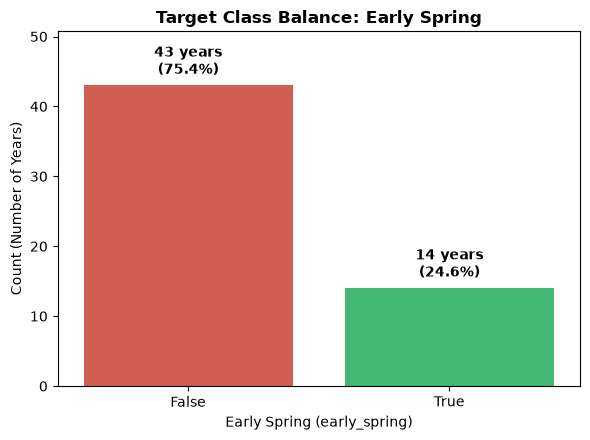

In [3]:
# Calculate counts and percentages
counts = data["early_spring"].value_counts()
pcts = data["early_spring"].value_counts(normalize=True) * 100

# Create bar plot
plt.figure(figsize=(6, 4.5))
ax = sns.barplot(
    x=counts.index.astype(str),
    y=counts.values,
    palette=["#e74c3c", "#2ecc71"],
)

# Chart styling
plt.title(
    "Target Class Balance: Early Spring", fontsize=12, fontweight="bold"
)
plt.xlabel("Early Spring (early_spring)", fontsize=10)
plt.ylabel("Count (Number of Years)", fontsize=10)
plt.ylim(0, max(counts.values) * 1.18)

# Add count and percentage labels above each bar
for i, (count, pct) in enumerate(zip(counts.values, pcts.values)):
  ax.text(
      i,
      count + 1,
      f"{count} years\n({pct:.1f}%)",
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
  )

plt.tight_layout()
plt.show()

There is a huge class imbalance with our target feature. only ~25% of the data is marked as early spring with the other 75% being a later or "on time" spring. This will need to be addressed later when we are training our models. I suspect if not handled, it will skew a lot of our predictions in favor of choosing false. Looking to the other variables we have collected, I think looking at soil temperature in association with the positive and negative early spring years will be beneficial

/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/4196447358.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/4196447358.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


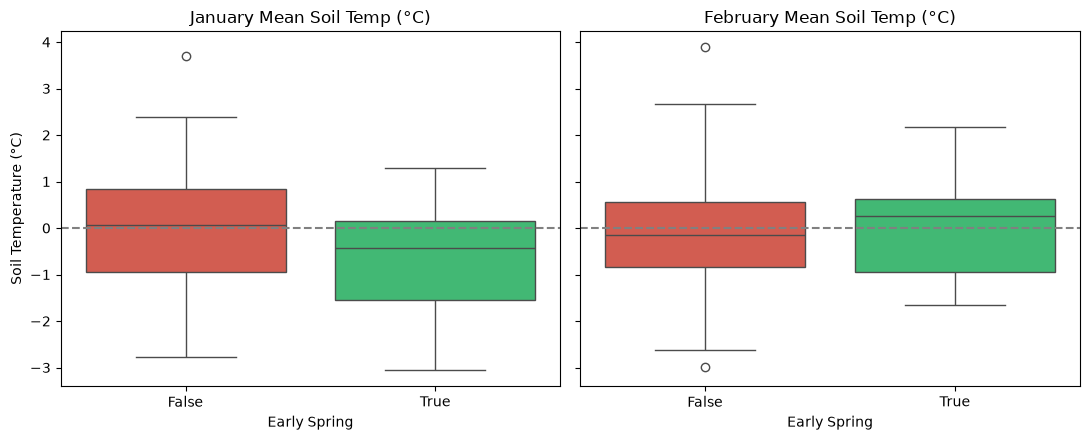

In [4]:
# Create two subplots that share the same Y-axis scale
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

# January
sns.boxplot(
    data=data,
    x="early_spring",
    y="soil_temp_mean_jan",
    ax=axes[0],
    palette=["#e74c3c", "#2ecc71"],
)
axes[0].set_title("January Mean Soil Temp (°C)")
axes[0].set_xlabel("Early Spring")
axes[0].set_ylabel("Soil Temperature (°C)")
axes[0].axhline(0, color="gray", linestyle="--")

# February
sns.boxplot(
    data=data,
    x="early_spring",
    y="soil_temp_mean_feb",
    ax=axes[1],
    palette=["#e74c3c", "#2ecc71"],
)
axes[1].set_title("February Mean Soil Temp (°C)")
axes[1].set_xlabel("Early Spring")
axes[1].axhline(0, color="gray", linestyle="--")

plt.tight_layout()
plt.show()

The difference in median soil temperature is quite high for both January and February. The difference in mean soil temperatures when going from January to February show high January median to lower February median for non early spring years and a low January median into higher February median for early spring years.

Looking at soil temperature, I have decided to divide them up by month by mean soil temp and if the mean temp resulted in an early spring or not. The first thing that sticks out to me is how lower January soil temperatures typically result in early spring. We can see that the early spring years go from a colder january to a warmer February. What is most interesting is how the median value for the subsequent february month for early spring years proceeds to get much warmer on average. Could the cold spikes in january show that the cold fronts experienced each year come sooner and would subsequently allow February months to be warmer? What is also interesting is that years that are not early spring show a much warmer January on average, whereas the February is around the same as the febraury months that result in an early spring year. My thought as to why this could be the case is possibly because the cold fronts come sooner in the winter and allow the lowest temperatures to hit January and taper off faster?

Also, this change in temperature from January to February makes me believe that a "temp delta" feature would be useful and insightful.

### January/February correlation with early_spring

Since a ton of our gathered data stems from dividing between January and February, we will see how the months fare in correlation with an early spring for snowfall, snow depth, max temp, mean temp, and freezing days

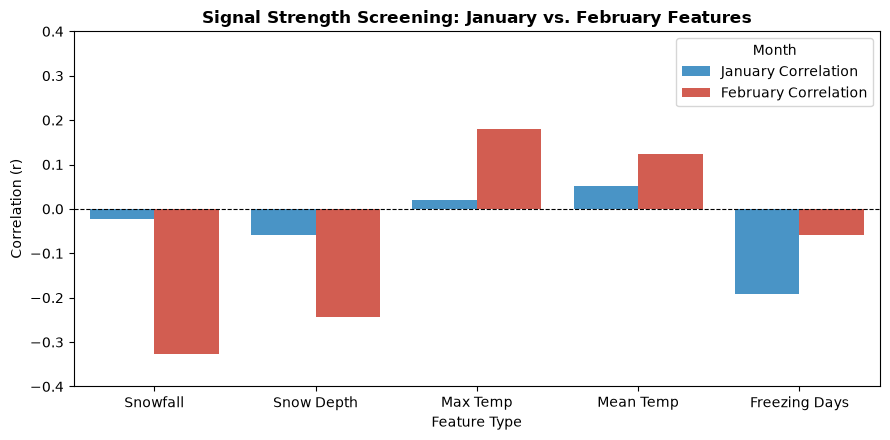

In [5]:
jan_vs_feb = pd.DataFrame(
    {
        "Feature Type": [
            "Snowfall",
            "Snow Depth",
            "Max Temp",
            "Mean Temp",
            "Freezing Days",
        ],
        "January Correlation": [
            data["farm_snowfall_sum_jan"].corr(data["early_spring"]),
            data["farm_snowdepth_mean_jan"].corr(data["early_spring"]),
            data["farm_max_temp_max_jan"].corr(data["early_spring"]),
            data["farm_avg_temp_mean_jan"].corr(data["early_spring"]),
            data["farm_freezing_days_jan"].corr(data["early_spring"]),
        ],
        "February Correlation": [
            data["farm_snowfall_sum_feb"].corr(data["early_spring"]),
            data["farm_snowdepth_mean_feb"].corr(data["early_spring"]),
            data["farm_max_temp_max_feb"].corr(data["early_spring"]),
            data["farm_avg_temp_mean_feb"].corr(data["early_spring"]),
            data["farm_freezing_days_feb"].corr(data["early_spring"]),
        ],
    }
)

melted_corrs = jan_vs_feb.melt(
    id_vars="Feature Type",
    value_vars=["January Correlation", "February Correlation"],
    var_name="Month",
    value_name="Correlation with Early Spring",
)

plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=melted_corrs,
    x="Feature Type",
    y="Correlation with Early Spring",
    hue="Month",
    palette=["#3498db", "#e74c3c"],
)
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.title(
    "Signal Strength Screening: January vs. February Features",
    fontsize=12,
    fontweight="bold",
)
plt.ylabel("Correlation (r)", fontsize=10)
plt.ylim(-0.4, 0.4)
plt.tight_layout()
plt.show()

Our barplot comparing January and February features to our target feature shows that most month divided features show little correlation between january and the target with the exception of freezing days. I think going forward we should reduce our exploration into only february since it shows an extremely skewed correlation in comparison to january. This will be really helpful in navigating the 40 so features we have in this dataframe. 

### Snow related stuff

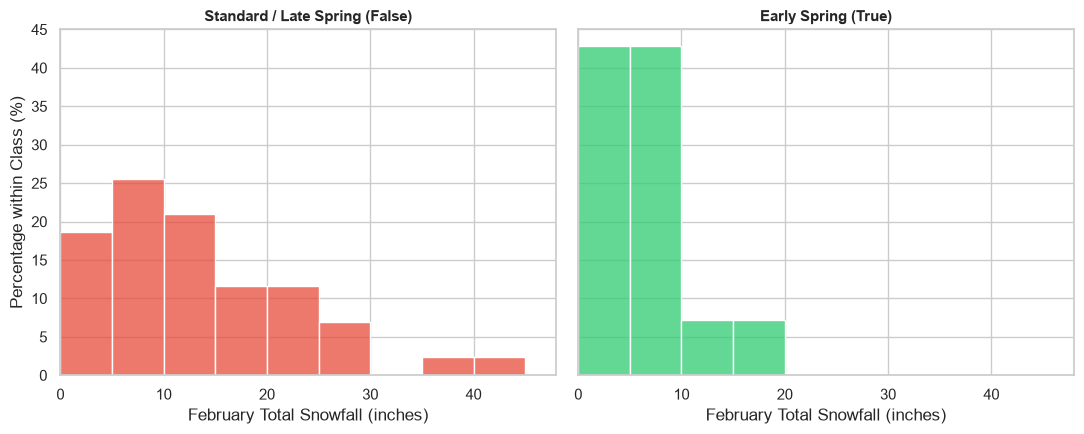

In [6]:
sns.set_theme(style="whitegrid")

# Create side-by-side subplots sharing BOTH X and Y axes
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, sharex=True)

# Define identical 5-inch bin widths from 0 to 50 for exact alignment
bins = range(0, 50, 5)

# Left Panel: Standard / Late Spring (False)
sns.histplot(
    data=data[~data["early_spring"]],
    x="farm_snowfall_sum_feb",
    color="#e74c3c",
    bins=bins,
    stat="percent",
    ax=axes[0],
)
axes[0].set_title(
    "Standard / Late Spring (False)", fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("February Total Snowfall (inches)")
axes[0].set_ylabel("Percentage within Class (%)")

# Right Panel: Early Spring (True)
sns.histplot(
    data=data[data["early_spring"]],
    x="farm_snowfall_sum_feb",
    color="#2ecc71",
    bins=bins,
    stat="percent",
    ax=axes[1],
)
axes[1].set_title("Early Spring (True)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("February Total Snowfall (inches)")

# Set explicit X-axis bounds on both plots
for ax in axes:
  ax.set_xlim(0, 48)

plt.tight_layout()
plt.show()

Looking at the total snowfall in February, majority of the early spring cases deal with snow that is under 10 inches in that given year. Noting the fact that we found earlier that only 25% of the data showed early spring makes this even more critical of a requirement. Also, as soon as you get above 20 inches of snow, the data no longer supports Early Spring. This makes sense since a lot of snow would make the ground much colder and also act as thermal protection for the ground below it, maintaining a much much cooler temperature leading into the scheduled spring for that year. Another thing to note is the steep drop after 10 inches of snow. Given our low amount of data as soon as it goes above ten we are only seeing a minimal amount of early springs. It is clear that snowfall has some influence in predicting an early spring, its almost as if you need low snow in february to have a chance at an early spring.

/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/3589819920.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


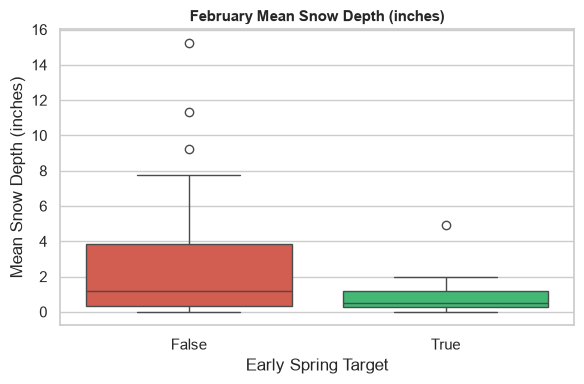

In [7]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4))

# Single simple boxplot
sns.boxplot(
    data=data,
    x="early_spring",
    y="farm_snowdepth_mean_feb",
    palette=["#e74c3c", "#2ecc71"],
)

plt.title("February Mean Snow Depth (inches)", fontsize=11, fontweight="bold")
plt.xlabel("Early Spring Target")
plt.ylabel("Mean Snow Depth (inches)")

plt.tight_layout()
plt.show()

Looking at the snow depth in February, it is clear that if there is consistent snow packed onto the ground the chance of early spring declines dramatically. We only see below 2 inches of average snowdepth producing an early spring, with the median being around 1.25 inches. Low snowfall is not definitive of early spring though, because non-early springs also fall into that range. Our outlier of about 5 inches shows that it is not impossible, and there is likely other factors that may have been at play to allow for such high average snowdepth to lead to an early spring. Also, there was a year that showed an average of 15 inches of snowdepth. That must have also been a winter where we previously saw total snowfall above 30-40inches.

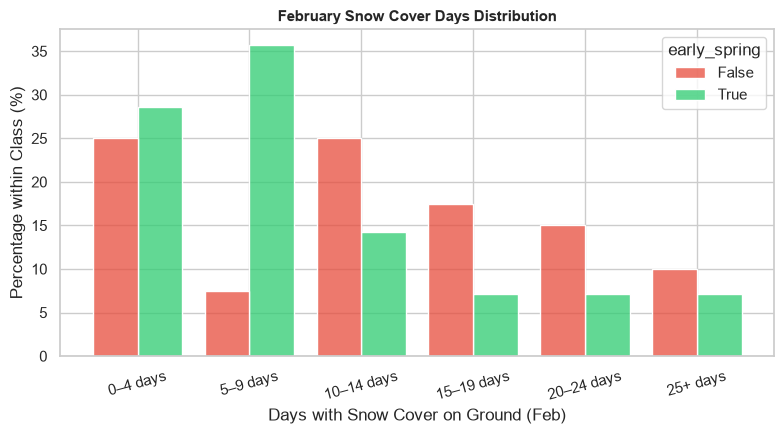

In [8]:
bins = [0, 5, 10, 15, 20, 25, 29]
labels = [
    "0–4 days",
    "5–9 days",
    "10–14 days",
    "15–19 days",
    "20–24 days",
    "25+ days",
]
data["snow_day_bin"] = pd.cut(
    data["farm_snow_cover_days_feb"], bins=bins, right=False, labels=labels
)

# 2. Set style and plot dodged bar chart
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 4.5))

sns.histplot(
    data=data,
    x="snow_day_bin",
    hue="early_spring",
    palette=["#e74c3c", "#2ecc71"],
    multiple="dodge",
    shrink=0.8,
    stat="percent",  # Normalizes class counts so imbalance doesn't skew heights
    common_norm=False,
)

plt.title(
    "February Snow Cover Days Distribution", fontsize=11, fontweight="bold"
)
plt.xlabel("Days with Snow Cover on Ground (Feb)")
plt.ylabel("Percentage within Class (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

For days with snow cover in February, we see a median snow cover for early spring years of 5-9 days (at 35% of the data) whereas non-early springs have a median of 10-14 days (at 25% of the data). We can also see that a large majority of early spring years show snow cover of less than a week to a little over less than a week. It seems that snow needs to not stay on the ground for long during february if an early spring is desired. All of the snow features we have seen so far support this idea. This makes a lot of sense because snow is both cold and can act as a great insulator of temperature. I think next it would be crucial to look into more temperature related features that look at both the air and ground.

### Air and Ground features

/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/4029991765.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/4029991765.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Standard/Late (False)", "Early Spring (True)"])
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/4029991765.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/4029991765.py:37: UserWarning: set_ticklabels() sho

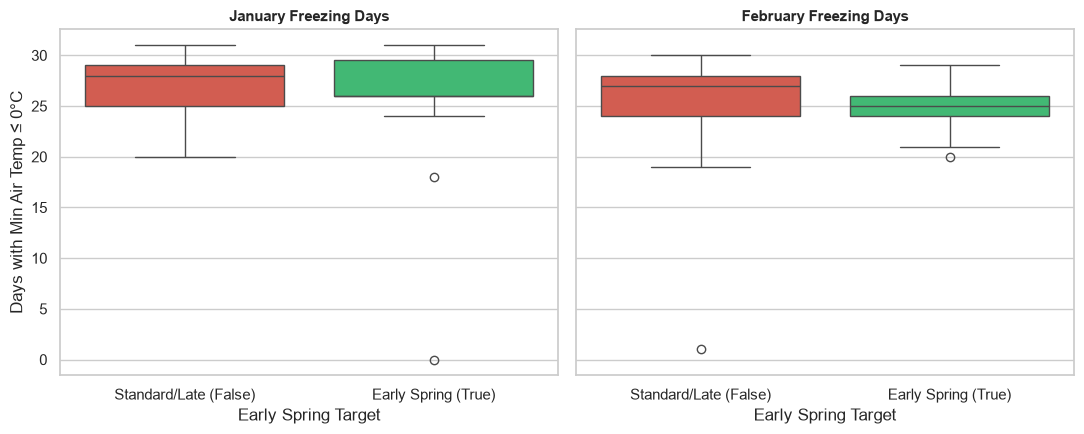

In [9]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

colors = ["#e74c3c", "#2ecc71"]  # Red = False, Green = True

# Subplot 1: January Air Freezing Days
sns.boxplot(
    data=data,
    x="early_spring",
    y="farm_freezing_days_jan",
    palette=colors,
    ax=axes[0],
)
axes[0].set_title(
    "January Freezing Days",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Early Spring Target")
axes[0].set_ylabel("Days with Min Air Temp ≤ 0°C")
axes[0].set_xticklabels(["Standard/Late (False)", "Early Spring (True)"])

# Subplot 2: February Air Freezing Days
sns.boxplot(
    data=data,
    x="early_spring",
    y="farm_freezing_days_feb",
    palette=colors,
    ax=axes[1],
)
axes[1].set_title(
    "February Freezing Days",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Early Spring Target")
axes[1].set_xticklabels(["Standard/Late (False)", "Early Spring (True)"])

plt.tight_layout()
plt.show()

Looking to the freezing days in January and February we see a noticeable difference in freezing days in the IQR for february whereas the IQR for january is about the same between Early and non-early springs. It seems though that all data in february is clustered in both months having almost every day see freezing temperatures (the cap is 28). We could drop February without significant loss in performance in our model we inevitably choose. These boxplots also made me think of a possible new feature, where we look to see if the freezing temperature happened during the day or at night, because that distinction could arguably show greater impact than looking at freezing days as a whole.

/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/2656046683.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/2656046683.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Standard/Late (False)", "Early Spring (True)"])
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/2656046683.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/2656046683.py:33: UserWarning: set_ticklabels() sho

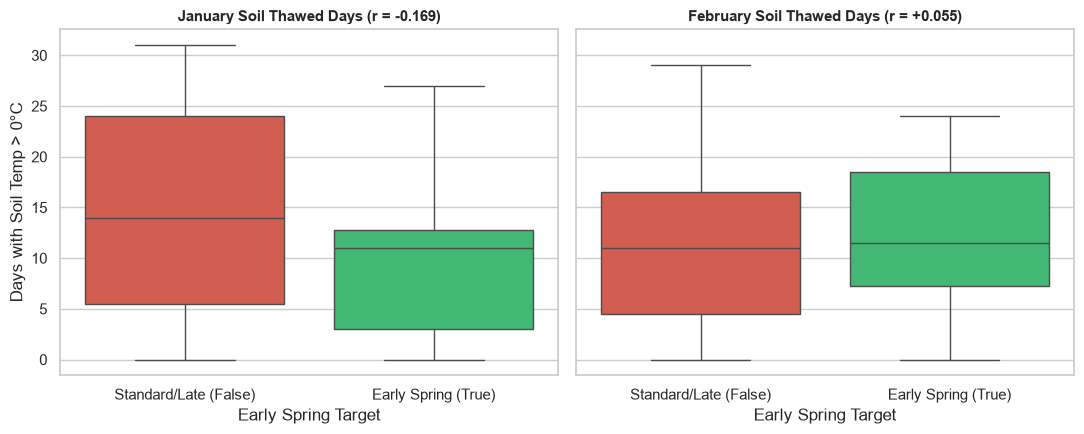

In [10]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

colors = ["#e74c3c", "#2ecc71"]

# Subplot 1: January Soil Thawed Days
sns.boxplot(
    data=data,
    x="early_spring",
    y="soil_thawed_days_jan",
    palette=colors,
    ax=axes[0],
)
axes[0].set_title(
    "January Soil Thawed Days (r = -0.169)", fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("Early Spring Target")
axes[0].set_ylabel("Days with Soil Temp > 0°C")
axes[0].set_xticklabels(["Standard/Late (False)", "Early Spring (True)"])

# Subplot 2: February Soil Thawed Days
sns.boxplot(
    data=data,
    x="early_spring",
    y="soil_thawed_days_feb",
    palette=colors,
    ax=axes[1],
)
axes[1].set_title(
    "February Soil Thawed Days (r = +0.055)", fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Early Spring Target")
axes[1].set_xticklabels(["Standard/Late (False)", "Early Spring (True)"])

plt.tight_layout()
plt.show()

The number of thawed days for both january and february looks a bit more promising. For january, this makes a lot of sense seeing early springs come when there are far less days with temperatures that have soil above 0 Celsius. It goes along with what we saw previously with soil temperatures, since both types of data are heavily related. If soil temp is low in january, we saw before that it shows higher chance of early spring. So if less days go above 0, its obvious that the soil temp would be lower overall. So we could probably get rid of this feature since we already see it in the soil temp average. There could also be some sort of delta related feature in here that could give more correlation to our target.

### ORI stuff:

/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/2310503114.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_86256/2310503114.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Standard/Late (False)", "Early Spring (True)"])


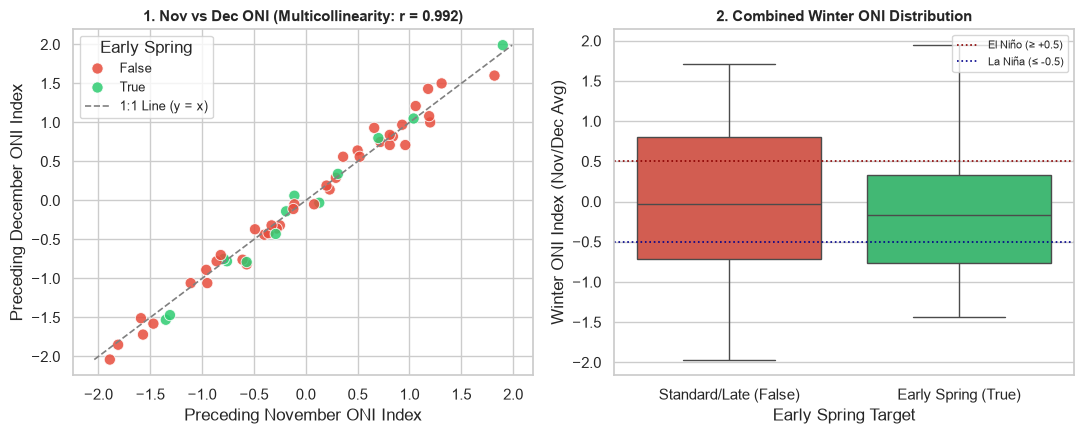

In [11]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

colors = ["#e74c3c", "#2ecc71"]  # Red = False, Green = True

# -------------------------------------------------------------------
# Subplot 1: Collinearity Scatter Plot (Nov vs Dec ONI)
# -------------------------------------------------------------------
sns.scatterplot(
    data=data,
    x="oni_prev_nov",
    y="oni_prev_dec",
    hue="early_spring",
    palette=colors,
    s=65,
    alpha=0.85,
    ax=axes[0],
)

# Add y = x reference line
min_val = min(data["oni_prev_nov"].min(), data["oni_prev_dec"].min())
max_val = max(data["oni_prev_nov"].max(), data["oni_prev_dec"].max())
axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="1:1 Line (y = x)",
)

axes[0].set_title(
    "1. Nov vs Dec ONI (Multicollinearity: r = 0.992)",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Preceding November ONI Index")
axes[0].set_ylabel("Preceding December ONI Index")
axes[0].legend(title="Early Spring", fontsize=9)

# -------------------------------------------------------------------
# Subplot 2: Winter ONI Average Distribution by Target Outcome
# -------------------------------------------------------------------
data["oni_winter_avg"] = data[["oni_prev_nov", "oni_prev_dec"]].mean(axis=1)

sns.boxplot(
    data=data,
    x="early_spring",
    y="oni_winter_avg",
    palette=colors,
    ax=axes[1],
)

# Benchmark thresholds for El Niño / La Niña phases
axes[1].axhline(
    0.5, color="darkred", linestyle=":", linewidth=1.2, label="El Niño (≥ +0.5)"
)
axes[1].axhline(
    -0.5,
    color="darkblue",
    linestyle=":",
    linewidth=1.2,
    label="La Niña (≤ -0.5)",
)

axes[1].set_title(
    "2. Combined Winter ONI Distribution", fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Early Spring Target")
axes[1].set_ylabel("Winter ONI Index (Nov/Dec Avg)")
axes[1].set_xticklabels(["Standard/Late (False)", "Early Spring (True)"])
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

We have two visuals here that we pulled out using ONI for Nov and Dec. The scatterplot on the left is showing that the relationship between the ONI of dec and nov is almost perfectly linear. This shows us that we dont actually need both features, and could benefit from making an average between the two. It would be redundant to include both. 

The second visual is demonstrating the combined distribution and its relationship with El Nino and La Nina's phase thresholds. Early springs are seen in our data to occur in both el nino and la nina, but the majority dont hit the threshold of El Nino. Standard and Late Spring springs unsurprisingly hit both. It is interesting though that most early springs (the IQR) sit in a range slightly below El Nino.

### 7-Days before March 1st Variables (the week leading into spring's beginning)

As requested, we have built some new features around this 7 day window each year leading into March 1st. We created a couple types of features, adding around 40 ish to the mix. These features include d-minus-n (1 to 7), 7 day means and 7 day trends. The d-minus-n features represent the metric produced for that specific day. So it allows us to look into the individual days inside the week before March 1st. The 7 day means take the week before March 1st of each year and aggregate it into it's mean. 7 day trends take the day that marks a week before march 1st and the day before march 1st, then finds the difference.

We were encouraged to take on these features because its the closest information we have leading up to our prediction. It could show high signal of what is to come since weather trends tend to change their consistent state slowly. 

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train_set = pd.read_parquet("train_set.parquet")
y = train_set["early_spring"].astype(int)

lag_cols  = [c for c in train_set.columns if "_d_minus_" in c]
mean_cols = [c for c in train_set.columns if c.endswith("_last_7d_mean")]

# 7-day trend = day before March 1 minus 7 days before (same definition as the preprocessor)
trend = pd.DataFrame(index=train_set.index)
for prefix in ["farm_avg_temp", "soil_mean_soil_temp", "om_temperature_2m_mean"]:
    d1, d7 = f"{prefix}_d_minus_1", f"{prefix}_d_minus_7"
    if d1 in train_set and d7 in train_set:
        trend[f"{prefix}_7d_trend"] = train_set[d1] - train_set[d7]

candidates = pd.concat([train_set[lag_cols + mean_cols], trend], axis=1)
print(f"{len(lag_cols)} daily lags, {len(mean_cols)} 7-day means, {trend.shape[1]} 7-day trends")

42 daily lags, 6 7-day means, 3 7-day trends


We were able to take the data before it was changed into yearly data, and pull out 42 features that use the daily lag (d-minus), 6 that take the 7 day mean, and 3 that use 7 day trends. Lets look at some missing values within these days. The 7 day take on the data pulls from the farm weather, soil and open meteo data we gathered initially.

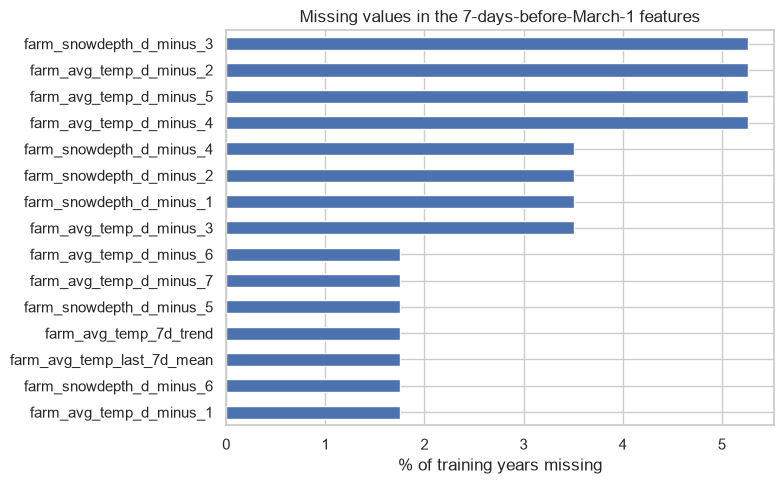

In [13]:
missing = candidates.isna().mean().mul(100).sort_values(ascending=False)
if (missing > 0).any():
    missing[missing > 0].head(15).sort_values().plot.barh(figsize=(8, 5))
    plt.xlabel("% of training years missing")
    plt.title("Missing values in the 7-days-before-March-1 features")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values in these features.")

Looking into the 7 days before, many of these 7 day related features have missing data, so imputation will be needed in the pipeline before we do any model testing and tuning.

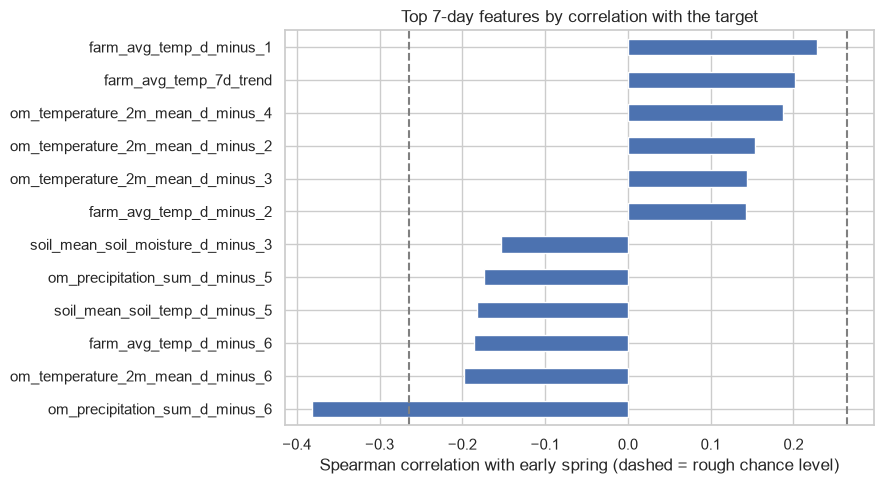

In [15]:
corr = candidates.apply(lambda col: col.corr(y, method="spearman")).dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(12)
chance = 2 / np.sqrt(len(y))  # rough "could be luck" level for n years

ax = top.sort_values().plot.barh(figsize=(9, 5))
ax.axvline(chance, color="gray", ls="--")
ax.axvline(-chance, color="gray", ls="--")
ax.set_xlabel("Spearman correlation with early spring (dashed = rough chance level)")
ax.set_title("Top 7-day features by correlation with the target")
plt.tight_layout()
plt.show()

AI suggested adding the Spearman correlation into the graph. It essentially shows where the correlation can be left to chance and uses ranks to fight against outliers and skewness. Honestly, most of this looks to be noise, not much to work with for the individual days in the week before M1st. However, the trends and means could be more promising...

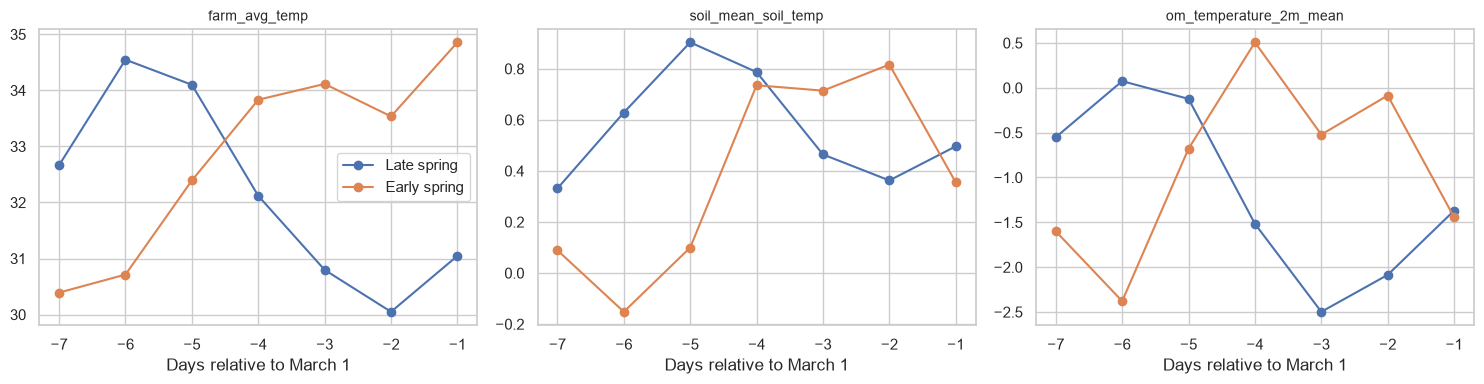

In [18]:
prefixes = [p for p in ["farm_avg_temp", "soil_mean_soil_temp", "om_temperature_2m_mean"]
            if f"{p}_d_minus_1" in train_set]
x = [-d for d in range(7, 0, -1)]  # -7 ... -1 days relative to March 1

fig, axes = plt.subplots(1, len(prefixes), figsize=(5 * len(prefixes), 4))
axes = np.atleast_1d(axes)
for ax, prefix in zip(axes, prefixes):
    for label, mask in [("Late spring", y == 0), ("Early spring", y == 1)]:
        means = [train_set.loc[mask, f"{prefix}_d_minus_{d}"].mean() for d in range(7, 0, -1)]
        ax.plot(x, means, marker="o", label=label)
    ax.set_title(prefix, fontsize=10)
    ax.set_xlabel("Days relative to March 1")
axes[0].legend()
plt.tight_layout()
plt.show()

The farm average temp looks to carry the most signal when looking to the trend along the week. This is because the two time series clearly have an indication of separation. By that I mean Late springs show a dive in temperature throughout the week before and Early springs show a rise in temperature. The other two, mean soil temp and the om temp dont give us much because the lines cross over multiple times. There is little distinction it seems. However, the places the lines diverge or have a large gap show slight promise, early week shows for Early Spring that it would favor colder temps rising to warmer ones. For OM-temp there should be a spike in temperature midweek?

### How would we solve this problem with what we have gathered?

To solve this problem manually, we would look to soil temperature, snowfall depth, and possibly the ORI index to form the basis of our prediction. A big observation would be if January proves to be a harsher winter month overall with low soil temps and good amount of snow and freezing temps.